# Bias-Variance Model Development

Country-of-origin models built up from a very small training set. Each stage starts from the previous stage's model, and every change follows the same rule:

- underfit (training macro F1 below 0.80, small gap): add capacity: higher C, bigger vocabulary, bigrams, then non-linear models (decision tree, gradient boosting)
- overfit (training macro F1 more than 0.10 above validation): add data, or regularize when no more data is available

The data grows by tasters, because taster and country are tangled in this dataset. Every stage also scores its model on validation reviews of the same countries written by other tasters, which shows where the models stop generalizing.

Model selection uses validation macro F1 only. The test split is not touched here.

In [1]:
import time

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.tree import DecisionTreeClassifier

SEED = 42
MIN_TRAIN_REVIEWS = 70
UNDERFIT_F1 = 0.80
OVERFIT_GAP = 0.10
BLUE = "#2a78d6"
GRAY = "#8a8984"
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

## Load

In [2]:
train = pd.read_parquet("data_clean/splits/train.parquet")
val = pd.read_parquet("data_clean/splits/val.parquet")
for split in (train, val):
    split["taster"] = split["taster_name"].fillna("Unknown")
counts = train["country"].value_counts()
COUNTRIES = list(counts[counts >= MIN_TRAIN_REVIEWS].index)
len(train), len(val), len(COUNTRIES)

(83945, 17988, 18)

## Helpers

In [3]:
def stage(split, tasters=None, countries=COUNTRIES):
    mask = split["country"].isin(countries)
    if tasters is not None:
        mask &= split["taster"].isin(tasters)
    return split[mask]


def others(split, tasters, countries):
    return split[split["country"].isin(countries) & ~split["taster"].isin(tasters)]


def sample(split, n):
    if n >= len(split):
        return split
    return split.groupby("country", group_keys=False).sample(frac=n / len(split), random_state=SEED)


def make_model(C=1.0, class_weight="balanced", kind="logreg"):
    if kind == "tree":
        return DecisionTreeClassifier(max_depth=30, min_samples_leaf=5, class_weight=class_weight, random_state=SEED)
    if kind == "boosting":
        return HistGradientBoostingClassifier(class_weight=class_weight, early_stopping=True, random_state=SEED)
    return LogisticRegression(C=C, class_weight=class_weight, max_iter=3000)


def fit_eval(tr, va, ngram=(1, 1), max_features=1000, extra=None, **model_args):
    vectorizer = TfidfVectorizer(ngram_range=ngram, min_df=2, max_df=0.9, sublinear_tf=True, max_features=max_features)
    vectorizer.fit(tr["description"])
    if model_args.get("kind") == "boosting":
        features = lambda d: vectorizer.transform(d["description"]).toarray().astype(np.float32)
    else:
        features = lambda d: vectorizer.transform(d["description"])
    X_tr = features(tr)
    model = make_model(**model_args)
    start = time.perf_counter()
    model.fit(X_tr, tr["country"])
    fit_seconds = time.perf_counter() - start
    pred_tr = model.predict(X_tr)
    pred_va = model.predict(features(va))
    result = {
        "n_train": len(tr),
        "train_F1": f1_score(tr["country"], pred_tr, average="macro"),
        "val_F1": f1_score(va["country"], pred_va, average="macro"),
        "val_accuracy": accuracy_score(va["country"], pred_va),
    }
    result["gap"] = result["train_F1"] - result["val_F1"]
    if extra is not None:
        result["other_taster_accuracy"] = accuracy_score(extra["country"], model.predict(features(extra)))
    result["fit_seconds"] = fit_seconds
    return result


def diagnose(result):
    if result["gap"] > OVERFIT_GAP:
        return "overfit"
    if result["train_F1"] < UNDERFIT_F1:
        return "underfit"
    return "ok"


log = []


def run(stage_name, configs, tr, va, extra=None):
    rows = []
    for change, cfg in configs.items():
        result = {"stage": stage_name, "change": change, **fit_eval(tr, va, extra=extra, **cfg)}
        result["diagnosis"] = diagnose(result)
        log.append(result)
        rows.append(result)
    return pd.DataFrame(rows).set_index("change").drop(columns="stage").round(3)


def learning_curve(tr, va, sizes, **cfg):
    return pd.DataFrame([fit_eval(sample(tr, n), va, **cfg) for n in sizes]).round(3)


def plot_scores(table, x, title, xlabel, logx=True):
    fig, ax = plt.subplots()
    ax.plot(table[x], table["train_F1"], color=GRAY, linewidth=2, marker="o", markersize=5, label="train")
    ax.plot(table[x], table["val_F1"], color=BLUE, linewidth=2, marker="o", markersize=5, label="validation")
    if logx:
        ax.set_xscale("log")
    ax.set(title=title, xlabel=xlabel, ylabel="Macro F1", ylim=(0, 1.02))
    ax.legend(frameon=False)
    return ax

## Stage 1: Roger Voss, France vs Portugal

In [4]:
S1 = (["Roger Voss"], ["France", "Portugal"])
s1_train, s1_val = stage(train, *S1), stage(val, *S1)
s1_small = sample(s1_train, 500)
pd.DataFrame({"train": s1_train["country"].value_counts(), "500 sample": s1_small["country"].value_counts(),
              "val": s1_val["country"].value_counts(), "other tasters (val)": others(val, *S1)["country"].value_counts()})

,train,500 sample,val,other tasters (val)
country,,,,
France,11992,383,2586,466
Portugal,3657,117,785,3


### Step 1: the simplest model

In [5]:
run("1: Voss FR/PT", {
    "1000 words, C=0.01": dict(max_features=1000, C=0.01, class_weight=None),
    "+ balanced class weights": dict(max_features=1000, C=0.01),
}, s1_small, s1_val)

,n_train,train_F1,val_F1,val_accuracy,gap,fit_seconds,diagnosis
change,,,,,,,
"1000 words, C=0.01",500,0.434,0.434,0.767,-0.000,0.003,underfit
+ balanced class weights,500,0.884,0.646,0.735,0.239,0.002,overfit


### Step 2: add capacity (C)

In [6]:
c_grid = run("1: Voss FR/PT", {f"C={C}": dict(max_features=1000, C=C) for C in [0.01, 0.1, 1, 10, 100]}, s1_small, s1_val)
c_grid

,n_train,train_F1,val_F1,val_accuracy,gap,fit_seconds,diagnosis
change,,,,,,,
C=0.01,500,0.884,0.646,0.735,0.239,0.003,overfit
C=0.1,500,0.889,0.651,0.745,0.238,0.003,overfit
C=1,500,0.941,0.656,0.755,0.285,0.004,overfit
C=10,500,0.992,0.654,0.763,0.338,0.005,overfit
C=100,500,1.000,0.645,0.761,0.355,0.006,overfit


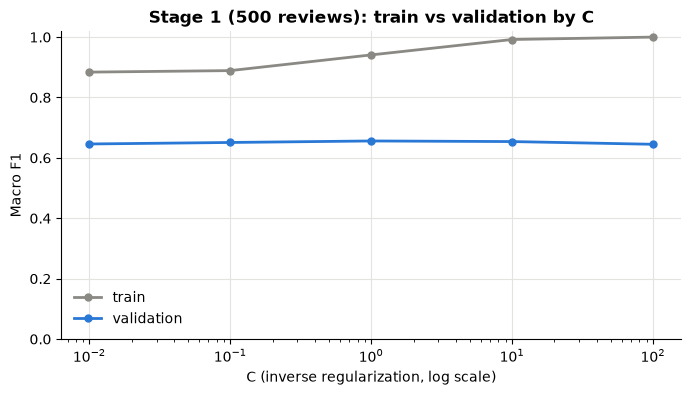

In [7]:
c_grid["C"] = [0.01, 0.1, 1, 10, 100]
plot_scores(c_grid, "C", "Stage 1 (500 reviews): train vs validation by C", "C (inverse regularization, log scale)");

### Step 3: add data

In [8]:
s1_curve = learning_curve(s1_train, s1_val, [250, 500, 1000, 2000, 4000, 8000, len(s1_train)], max_features=1000, C=10)
s1_curve

,n_train,train_F1,val_F1,val_accuracy,gap,fit_seconds
0,250,1.000,0.627,0.762,0.373,0.004
1,500,0.992,0.654,0.763,0.338,0.004
2,1000,0.965,0.683,0.772,0.282,0.008
3,2000,0.927,0.713,0.787,0.213,0.010
4,4000,0.874,0.737,0.800,0.136,0.018
5,8000,0.835,0.748,0.807,0.087,0.041
6,15649,0.808,0.764,0.818,0.044,0.099


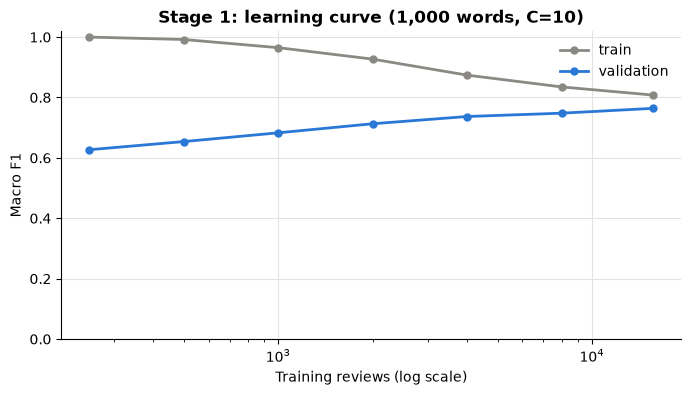

In [9]:
plot_scores(s1_curve, "n_train", "Stage 1: learning curve (1,000 words, C=10)", "Training reviews (log scale)");

### Step 4: capacity again on all of Stage 1

In [10]:
s1_capacity = run("1: Voss FR/PT", {
    "1000 words, C=10": dict(max_features=1000, C=10),
    "5000 words, C=10": dict(max_features=5000, C=10),
    "5000 words, C=1": dict(max_features=5000, C=1),
    "5000 words, C=3": dict(max_features=5000, C=3),
    "20000 words+bigrams, C=10": dict(ngram=(1, 2), max_features=20000, C=10),
    "decision tree, 5000 words": dict(max_features=5000, kind="tree"),
    "gradient boosting, 5000 words": dict(max_features=5000, kind="boosting"),
}, s1_train, s1_val)
s1_capacity

,n_train,train_F1,val_F1,val_accuracy,gap,fit_seconds,diagnosis
change,,,,,,,
"1000 words, C=10",15649,0.808,0.764,0.818,0.044,0.097,ok
"5000 words, C=10",15649,0.876,0.785,0.838,0.091,0.132,ok
"5000 words, C=1",15649,0.837,0.783,0.837,0.054,0.073,ok
"5000 words, C=3",15649,0.859,0.788,0.840,0.071,0.107,ok
"20000 words+bigrams, C=10",15649,0.978,0.777,0.842,0.201,0.443,overfit
"decision tree, 5000 words",15649,0.807,0.688,0.763,0.118,2.452,overfit
"gradient boosting, 5000 words",15649,0.873,0.774,0.833,0.099,27.957,ok


## Stages 2-4: more tasters, more countries

Each stage keeps the Stage 1 choice and re-checks the capacity settings around it. other_taster_accuracy scores the model on validation reviews of the same countries by tasters outside the stage.

In [11]:
STAGES = {
    "2: Voss 3 countries": (["Roger Voss"], ["France", "Portugal", "Austria"]),
    "3: + Schachner": (["Roger Voss", "Michael Schachner"], ["France", "Portugal", "Austria", "Spain", "Chile", "Argentina"]),
    "4: 4 multi-country tasters": (["Roger Voss", "Michael Schachner", "Joe Czerwinski", "Anna Lee C. Iijima"],
                                   ["France", "Portugal", "Austria", "Spain", "Chile", "Argentina",
                                    "Australia", "New Zealand", "Germany", "US"]),
}
STAGE_CONFIGS = {
    "5000 words, C=1": dict(max_features=5000, C=1),
    "5000 words, C=3": dict(max_features=5000, C=3),
    "5000 words, C=10": dict(max_features=5000, C=10),
    "20000 words+bigrams, C=3": dict(ngram=(1, 2), max_features=20000, C=3),
}
stage_tables = {}
for name, (tasters, countries) in STAGES.items():
    tr, va, ex = stage(train, tasters, countries), stage(val, tasters, countries), others(val, tasters, countries)
    stage_tables[name] = run(name, STAGE_CONFIGS, tr, va, extra=ex)
pd.concat(stage_tables)

n_train  train_F1  \
                           change                                        
2: Voss 3 countries        5000 words, C=1             16418     0.782   
                           5000 words, C=3             16418     0.821   
                           5000 words, C=10            16418     0.861   
                           20000 words+bigrams, C=3    16418     0.931   
3: + Schachner             5000 words, C=1             25974     0.785   
                           5000 words, C=3             25974     0.827   
                           5000 words, C=10            25974     0.870   
                           20000 words+bigrams, C=3    25974     0.932   
4: 4 multi-country tasters 5000 words, C=1             32010     0.799   
                           5000 words, C=3             32010     0.846   
                           5000 words, C=10            32010     0.890   
                           20000 words+bigrams, C=3    32010     0.921   

                                                     val_F1  val_accuracy  \
                           change                                           
2: Voss 3 countries        5000 words, C=1            0.678         0.793   
                           5000 words, C=3            0.687         0.798   
                           5000 words, C=10           0.686         0.800   
                           20000 words+bigrams, C=3   0.701         0.809   
3: + Schachner             5000 words, C=1            0.660         0.741   
                           5000 words, C=3            0.658         0.742   
                           5000 words, C=10           0.649         0.737   
                           20000 words+bigrams, C=3   0.658         0.742   
4: 4 multi-country tasters 5000 words, C=1            0.672         0.723   
                           5000 words, C=3            0.672         0.726   
                           5000 words, C=10           0.667         0.726   
                           20000 words+bigrams, C=3   0.673         0.730   

                                                       gap  \
                           change                            
2: Voss 3 countries        5000 words, C=1           0.105   
                           5000 words, C=3           0.135   
                           5000 words, C=10          0.174   
                           20000 words+bigrams, C=3  0.230   
3: + Schachner             5000 words, C=1           0.125   
                           5000 words, C=3           0.169   
                           5000 words, C=10          0.221   
                           20000 words+bigrams, C=3  0.275   
4: 4 multi-country tasters 5000 words, C=1           0.127   
                           5000 words, C=3           0.174   
                           5000 words, C=10          0.223   
                           20000 words+bigrams, C=3  0.248   

                                                     other_taster_accuracy  \
                           change                                            
2: Voss 3 countries        5000 words, C=1                           0.572   
                           5000 words, C=3                           0.556   
                           5000 words, C=10                          0.541   
                           20000 words+bigrams, C=3                  0.558   
3: + Schachner             5000 words, C=1                           0.205   
                           5000 words, C=3                           0.209   
                           5000 words, C=10                          0.222   
                           20000 words+bigrams, C=3                  0.198   
4: 4 multi-country tasters 5000 words, C=1                           0.237   
                           5000 words, C=3                           0.249   
                           5000 words, C=10                          0.248   
                           20000 words+bigrams, C=3   

### Where the models stop generalizing

In [12]:
T3, C3 = STAGES["3: + Schachner"]
s3_train = stage(train, T3, C3)
vectorizer = TfidfVectorizer(min_df=2, max_df=0.9, sublinear_tf=True, max_features=5000)
s3_model = make_model(C=3).fit(vectorizer.fit_transform(s3_train["description"]), s3_train["country"])
s3_others = others(val, T3, C3).copy()
s3_others["predicted"] = s3_model.predict(vectorizer.transform(s3_others["description"]))
pd.crosstab([s3_others["country"], s3_others["taster"]], s3_others["predicted"]).loc[lambda d: d.sum(axis=1) >= 20]

predicted                 Argentina  Austria  Chile  France  Portugal  Spain
country taster                                                              
Austria Anne Krebiehl MW         19       59     90      56         7     74
France  Anne Krebiehl MW         14       27     51      32         6     64
        Joe Czerwinski           14        2     33      42         4     57
        Lauren Buzzeo            12        0     13       7         6     40
        Unknown                   3        1      2       5         0     22

## Stage 5: all tasters, all 18 countries

In [13]:
s5_train, s5_val = stage(train), stage(val)
S5_CONFIGS = {
    "5000 words, C=3": dict(max_features=5000, C=3),
    "5000 words, C=10": dict(max_features=5000, C=10),
    "10000 words, C=3": dict(max_features=10000, C=3),
    "10000 words, C=10": dict(max_features=10000, C=10),
    "20000 words+bigrams, C=3": dict(ngram=(1, 2), max_features=20000, C=3),
    "20000 words+bigrams, C=10": dict(ngram=(1, 2), max_features=20000, C=10),
    "5000 words, C=10, no class weights": dict(max_features=5000, C=10, class_weight=None),
    "decision tree, 10000 words": dict(max_features=10000, kind="tree"),
}
s5_grid = run("5: all", S5_CONFIGS, s5_train, s5_val)
s5_grid

,n_train,train_F1,val_F1,val_accuracy,gap,fit_seconds,diagnosis
change,,,,,,,
"5000 words, C=3",83350,0.770,0.563,0.810,0.206,41.024,overfit
"5000 words, C=10",83350,0.827,0.575,0.822,0.253,34.604,overfit
"10000 words, C=3",83350,0.801,0.607,0.820,0.194,15.431,overfit
"10000 words, C=10",83350,0.861,0.612,0.830,0.249,20.966,overfit
"20000 words+bigrams, C=3",83350,0.872,0.600,0.837,0.272,27.374,overfit
"20000 words+bigrams, C=10",83350,0.936,0.595,0.844,0.341,34.836,overfit
"5000 words, C=10, no class weights",83350,0.866,0.598,0.857,0.268,24.334,overfit
"decision tree, 10000 words",83350,0.503,0.265,0.483,0.238,36.806,overfit


In [14]:
FINAL_NAME = s5_grid["val_F1"].idxmax()
FINAL_NAME

'10000 words, C=10'

In [15]:
s5_curve = learning_curve(s5_train, s5_val, [1000, 3000, 10000, 30000, len(s5_train)], **S5_CONFIGS[FINAL_NAME])
s5_curve

,n_train,train_F1,val_F1,val_accuracy,gap,fit_seconds
0,1000,0.997,0.308,0.727,0.688,0.230
1,2999,0.982,0.409,0.771,0.573,0.797
2,9998,0.961,0.529,0.804,0.431,2.100
3,29998,0.923,0.578,0.821,0.344,9.716
4,83350,0.861,0.612,0.830,0.249,21.502


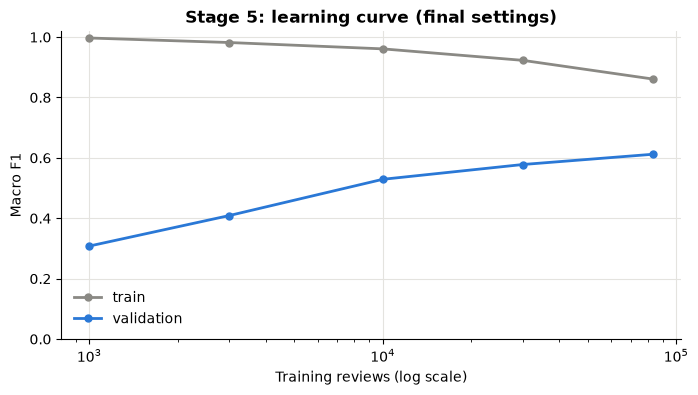

In [16]:
plot_scores(s5_curve, "n_train", "Stage 5: learning curve (final settings)", "Training reviews (log scale)");

## Comparison with the baseline

In [17]:
baseline_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True, max_features=20000)
X_tr = baseline_vectorizer.fit_transform(s5_train["description"])
X_va = baseline_vectorizer.transform(s5_val["description"])
baseline = LogisticRegression(C=10, max_iter=3000).fit(X_tr, s5_train["country"])
pd.DataFrame({
    "baseline (bigrams, 20000, C=10, unweighted)": {
        "train_F1": f1_score(s5_train["country"], baseline.predict(X_tr), average="macro"),
        "val_F1": f1_score(s5_val["country"], baseline.predict(X_va), average="macro"),
        "val_accuracy": accuracy_score(s5_val["country"], baseline.predict(X_va)),
    },
    "bias-variance final": s5_grid.loc[FINAL_NAME, ["train_F1", "val_F1", "val_accuracy"]],
}).T.round(3)

,train_F1,val_F1,val_accuracy
"baseline (bigrams, 20000, C=10, unweighted)",0.972343,0.574967,0.856871
bias-variance final,0.861,0.612,0.83


## Experiment log

In [18]:
pd.DataFrame(log)[["stage", "change", "n_train", "train_F1", "val_F1", "gap", "other_taster_accuracy", "diagnosis"]].round(3)

,stage,change,n_train,train_F1,val_F1,gap,other_taster_accuracy,diagnosis
0,1: Voss FR/PT,"1000 words, C=0.01",500,0.434,0.434,-0.000,NaN,underfit
1,1: Voss FR/PT,+ balanced class weights,500,0.884,0.646,0.239,NaN,overfit
2,1: Voss FR/PT,C=0.01,500,0.884,0.646,0.239,NaN,overfit
3,1: Voss FR/PT,C=0.1,500,0.889,0.651,0.238,NaN,overfit
4,1: Voss FR/PT,C=1,500,0.941,0.656,0.285,NaN,overfit
5,1: Voss FR/PT,C=10,500,0.992,0.654,0.338,NaN,overfit
6,1: Voss FR/PT,C=100,500,1.000,0.645,0.355,NaN,overfit
7,1: Voss FR/PT,"1000 words, C=10",15649,0.808,0.764,0.044,NaN,ok
8,1: Voss FR/PT,"5000 words, C=10",15649,0.876,0.785,0.091,NaN,ok
9,1: Voss FR/PT,"5000 words, C=1",15649,0.837,0.783,0.054,NaN,ok


## Summary

- Stage 1 started underfit for the wrong reason (class imbalance), then overfit at every C on 500 reviews. Adding data closed the gap from 0.37 to 0.04, after which a larger vocabulary helped.
- From Stage 2 on, every model overfits, and changing C or vocabulary size, or adding bigrams, moves validation F1 by about 0.02 at most. Decision trees and gradient boosting never beat logistic regression. The limit is data and the problem itself, not model capacity.
- Models stop generalizing across tasters. A two-taster model labels about 21% of other tasters' reviews of the same countries correctly. A large share of the origin signal is taster style.
- Final: logistic regression, 10,000 unigrams, C=10, balanced weights. Validation macro F1 0.612, accuracy 0.830. The test set has not been used.